# 03 Analyse: cost benchmark
Which towns cost more than they should, given who lives there? Which care types cause it? Does poor health explain it?

In [1]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt

## Step 1. Reference rates: national cost per insured-year by sex and age

In [2]:
# Load the clean Vektis table
vektis = pd.read_csv("../data/processed/vektis_clean.csv")

In [3]:
# Check Vektis shape
vektis.shape

(12991, 45)

In [4]:
# One row per age(19 age bands) and sex(2, m,v ) group = 38 groups(2*19), total cost and insured-year
# Right now I have 12,991 rows (one per town × sex × age). I want 38

# National totals per sex and age group: sum cost and insured-years over all towns
rates = vektis.groupby(["geslacht", "age_from"])[["cost_total", "aantal_verzekerdejaren"]].sum()

rates.shape

(38, 2)

In [5]:
# rate = the national average cost per person (per insured-year) for one sex and age group. 
# Reference rate: national average cost per insured-year, per sex and age group
rates["rate"] = rates["cost_total"] / rates["aantal_verzekerdejaren"]

In [6]:
# Move sex and age out of the index into normal columns, so they can be filtered and plotted
rates_flat = rates.reset_index()

rates_flat.shape

(38, 5)

In [7]:
# One table per sex, so each gets its own line in the chart
men = rates_flat[rates_flat["geslacht"] == "M"]
women = rates_flat[rates_flat["geslacht"] == "V"]
len(men), len(women)

(19, 19)

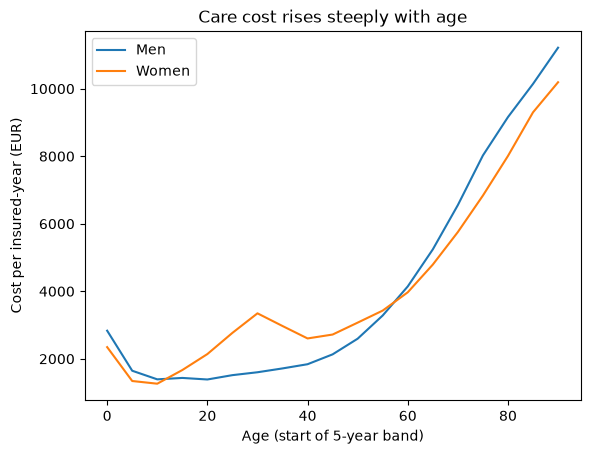

In [8]:
# Sanity chart: national cost per insured-year by age, one line per sex
plt.plot(men["age_from"], men["rate"], label="Men")
plt.plot(women["age_from"], women["rate"], label="Women")
plt.xlabel("Age (start of 5-year band)")
plt.ylabel("Cost per insured-year (EUR)")
plt.title("Care cost rises steeply with age")
plt.legend()
plt.show()


Cost per person depends heavily on age and sex: a man of 90 costs about 8 times as much as a man of 20. So a town's raw cost mostly reflects who lives there. To compare towns fairly, each town must be measured against what its own age and sex mix would cost.



## Step 2. Expected cost and cost index per town

In [9]:
# Adding the rate column (the national average cost per insured-year for each sex and age group) from rates_flat to the Vektis table, matched on geslacht and age_from
# Give every Vektis row the national rate of its own sex and age group
# Take only the 2 key columns and the rate from rates_flat, so no _x/_y columns appear
vektis_rated = pd.merge(vektis, rates_flat[["geslacht", "age_from", "rate"]], on=["geslacht", "age_from"], how="left")


In [10]:
# Check: still 12,991 rows (one new column, rate) and no row without a rate
print("Shape:", vektis_rated.shape)
print("Rows without a rate:", vektis_rated["rate"].isna().sum())
assert len(vektis_rated) == 12991
assert vektis_rated["rate"].notna().all()


Shape: (12991, 46)
Rows without a rate: 0


In [11]:
# Expected cost per row: insured-years x national rate of that sex and age group
vektis_rated["expected"] = vektis_rated["aantal_verzekerdejaren"] * vektis_rated["rate"]

In [12]:
# Check: national expected cost must equal national actual cost (rates came from the same data)
print("Expected total:", round(vektis_rated["expected"].sum()))
print("Actual total:  ", round(vektis_rated["cost_total"].sum()))

# The rates were made from this same data (national cost ÷ national insured-years per group). Multiplying back by the same insured-years and adding everything up gives the same total. If they differed, the merge in 2a would be wrong.

Expected total: 59357400091
Actual total:   59357400091


In [13]:
# One row per town: add up actual cost, expected cost and insured-years over all sex and age groups
vektis_town = vektis_rated.groupby(["Key", "gemeentenaam"])[["cost_total", "expected", "aantal_verzekerdejaren"]].sum().reset_index()

In [14]:
# Check: 342 towns, 5 columns; look at Amsterdam
print("Shape:", vektis_town.shape)
assert len(vektis_town) == 342
vektis_town[vektis_town["Key"] == "GM0363"]

Shape: (342, 5)


,Key,gemeentenaam,cost_total,expected,aantal_verzekerdejaren
106,GM0363,AMSTERDAM,2.756174e+09,2.682914e+09,887918.59


In [15]:
# KPIs per town
# Per person: divide each total by the town's insured-years

# actual_per_person: what one insured-year really cost in this town
vektis_town["actual_per_person"] = vektis_town["cost_total"] / vektis_town["aantal_verzekerdejaren"]

# expected_per_person: what it would cost at the national rates
vektis_town["expected_per_person"] = vektis_town["expected"] / vektis_town["aantal_verzekerdejaren"]

# cost_index: actual ÷ expected × 100. The headline KPI
vektis_town["cost_index"] = vektis_town["cost_total"] / vektis_town["expected"] * 100

# excess: actual − expected, in euros: how much money the gap is
vektis_town["excess"] = vektis_town["cost_total"] - vektis_town["expected"]

In [16]:
# Check: Amsterdam (GM0363) and Utrecht (GM0344)
vektis_town[vektis_town["Key"].isin(["GM0363", "GM0344"])]

,Key,gemeentenaam,cost_total,expected,aantal_verzekerdejaren,actual_per_person,expected_per_person,cost_index,excess
96,GM0344,UTRECHT,1.053971e+09,1.029987e+09,363686.77,2898.019557,2832.070660,102.328646,2.398474e+07
106,GM0363,AMSTERDAM,2.756174e+09,2.682914e+09,887918.59,3104.084035,3021.576103,102.730626,7.326033e+07


**What the KPIs say for the two biggest cities:** after adjusting for age and sex, Amsterdam costs 2.7% more than its population mix predicts (cost index 102.7), about €73 million a year above expected. Utrecht is 2.3% above expected (index 102.3), about €24 million. Both indexes are close to 100, but because these cities are large, a small percentage is a lot of money. This is why the benchmark shows the index and the euros side by side.


In [17]:
# Stop if national expected and actual totals differ (would mean the merge in 2a is wrong)
assert round(vektis_rated["expected"].sum()) == round(vektis_rated["cost_total"].sum()), "Expected total does not equal actual total"

In [18]:
# Peek at the town table: one row per town with actual, expected and insured-years
vektis_town.head()

,Key,gemeentenaam,cost_total,expected,aantal_verzekerdejaren,actual_per_person,expected_per_person,cost_index,excess
0,GM0014,GRONINGEN,7.360728e+08,7.011526e+08,228482.93,3221.565753,3068.730996,104.980390,3.492013e+07
1,GM0034,ALMERE,6.832099e+08,6.657136e+08,222940.28,3064.542090,2986.062575,102.628194,1.749625e+07
2,GM0037,STADSKANAAL,1.394910e+08,1.164892e+08,31289.31,4458.105281,3722.972022,119.745871,2.300181e+07
3,GM0047,VEENDAM,1.142761e+08,9.746109e+07,27376.82,4174.190746,3559.985654,117.253022,1.681498e+07
4,GM0050,ZEEWOLDE,6.930273e+07,7.354691e+07,23206.62,2986.334531,3169.220939,94.229294,-4.244175e+06


In [19]:
# Checksums: the whole country compared with itself must come out exactly as expected. a test to chcek if the benchmark is wired correctly
# If the whole country is compared with itself, it must come out exactly as expected: index 100, excess €0. If not, something is wrong, and every finding after this would be wrong too

# National cost index: total actual / total expected x 100, as if the country were one town
national_index = vektis_town["cost_total"].sum() / vektis_town["expected"].sum() * 100

# Total excess: add up the excess of all 342 towns (above and below expected cancel out)
total_excess = vektis_town["excess"].sum()

print("National cost index:", round(national_index, 1))
print("Total excess (EUR):", round(total_excess))

# Stop if either checksum fails
assert round(national_index, 1) == 100, "National index is not 100: check the expected cost"
assert round(total_excess) == 0, "Total excess is not 0: check the expected cost"

National cost index: 100.0
Total excess (EUR): 0


In [20]:
# The spread of the cost index across towns: expect min about 77, max about 125, median about 97
vektis_town["cost_index"].describe()

count    342.000000
mean      97.414438
std        7.108902
min       77.471100
25%       92.861894
50%       96.836937
75%      101.495449
max      125.417237
Name: cost_index, dtype: float64

The big cities (Amsterdam, Utrecht) sit above 100, and they carry a large share of all the money. Because the national index is exactly 100, the many small towns must sit slightly below 100 to balance them. The median counts every town once, the national index counts every euro once, so the median town comes out at 96.8.



In [21]:
# KPIs per care type. The per-care-type index says what causes it

# Step 2f-1: reshape from wide to long, one row per town x sex x age x care type
# The 10 care-type group columns made in 02_clean, Step 5
care_types = ["Hospital care", "Pharmacy", "GP care", "Mental health", "Nursing and rehabilitation",
              "Paramedical", "Aids and dental", "Maternity", "Care abroad", "Transport and other"]

# id_vars stay as they are in every row; the 10 care-type columns become two columns: care_type and cost
vektis_long = vektis.melt(id_vars=["Key", "gemeentenaam", "geslacht", "age_from", "aantal_verzekerdejaren"],
                          value_vars=care_types, var_name="care_type", value_name="cost")

In [22]:
# Check: 12,991 rows x 10 care types = 129,910 rows, 7 columns; the cost still adds up to the national total
print("Shape:", vektis_long.shape)
assert len(vektis_long) == 12991 * 10
assert round(vektis_long["cost"].sum()) == round(vektis["cost_total"].sum()), "Melt lost or added cost"
vektis_long.head(3)

Shape: (129910, 7)


,Key,gemeentenaam,geslacht,age_from,aantal_verzekerdejaren,care_type,cost
0,GM1680,AA EN HUNZE,M,0,462.82,Hospital care,594197.18
1,GM0358,AALSMEER,M,0,665.75,Hospital care,1829500.58
2,GM0197,AALTEN,M,0,596.80,Hospital care,862338.30


In [23]:
# Step 2f-2: national reference rate per care type x sex x age group
# National totals: sum cost and insured-years over all towns, per care type, sex and age
rates_ct = vektis_long.groupby(["care_type", "geslacht", "age_from"])[["cost", "aantal_verzekerdejaren"]].sum()

# Rate: national average cost per insured-year for that care type, sex and age group
rates_ct["rate"] = rates_ct["cost"] / rates_ct["aantal_verzekerdejaren"]

# Move care type, sex and age out of the index into normal columns, for the merge in 2f-3
rates_ct_flat = rates_ct.reset_index()


In [24]:
# Check: 10 care types x 38 groups = 380 rates
print("Shape:", rates_ct_flat.shape)
assert len(rates_ct_flat) == 380
rates_ct_flat.head(3)

Shape: (380, 6)


,care_type,geslacht,age_from,cost,aantal_verzekerdejaren,rate
0,Aids and dental,M,0,3.050211e+07,390153.04,78.179860
1,Aids and dental,M,5,1.244383e+08,448758.44,277.294675
2,Aids and dental,M,10,1.375595e+08,474631.49,289.823700


In [25]:
# Step 2f-3: give every row the national rate of its own care type, sex and age group
# Take only the 3 key columns and the rate from rates_ct_flat, so no _x/_y columns appear
vektis_long_rated = pd.merge(vektis_long, rates_ct_flat[["care_type", "geslacht", "age_from", "rate"]],
                             on=["care_type", "geslacht", "age_from"], how="left")


In [26]:
# Check: still 129,910 rows (one new column, rate) and no row without a rate
print("Shape:", vektis_long_rated.shape)
print("Rows without a rate:", vektis_long_rated["rate"].isna().sum())
assert len(vektis_long_rated) == 129910, "The merge added rows: check on= has all 3 keys"
assert vektis_long_rated["rate"].notna().all()


Shape: (129910, 8)
Rows without a rate: 0


Each row now has its own insured-years and the national rate for its care type, sex and age, which is everything needed to compute what that row should cost.

In [27]:
# Expected cost per row: insured-years x national rate for that care type, sex and age group
vektis_long_rated["expected"] = vektis_long_rated["aantal_verzekerdejaren"] * vektis_long_rated["rate"]

In [28]:
# Check: national expected cost must equal national actual cost, as in 2b
print("Expected total:", round(vektis_long_rated["expected"].sum()))
print("Actual total:  ", round(vektis_long_rated["cost"].sum()))
assert round(vektis_long_rated["expected"].sum()) == round(vektis_long_rated["cost"].sum()), "Expected total does not equal actual total"

Expected total: 59357400091
Actual total:   59357400091


In [29]:
# Step 2f-5: one row per town and care type: add up actual cost, expected cost and insured-years over all sex and age groups
care_type_town = vektis_long_rated.groupby(["Key", "gemeentenaam", "care_type"])[["cost", "expected", "aantal_verzekerdejaren"]].sum().reset_index()


In [30]:
# Check: 342 towns x 10 care types = 3,420 rows; look at Amsterdam's 10 care types
print("Shape:", care_type_town.shape)
assert len(care_type_town) == 342 * 10
care_type_town[care_type_town["Key"] == "GM0363"]


Shape: (3420, 6)


,Key,gemeentenaam,care_type,cost,expected,aantal_verzekerdejaren
1060,GM0363,AMSTERDAM,Aids and dental,1.206868e+08,1.256469e+08,887918.59
1061,GM0363,AMSTERDAM,Care abroad,2.176847e+07,1.600548e+07,887918.59
1062,GM0363,AMSTERDAM,GP care,2.549129e+08,2.486597e+08,887918.59
1063,GM0363,AMSTERDAM,Hospital care,1.327655e+09,1.376090e+09,887918.59
1064,GM0363,AMSTERDAM,Maternity,4.065125e+07,5.940374e+07,887918.59
1065,GM0363,AMSTERDAM,Mental health,4.177775e+08,3.220836e+08,887918.59
1066,GM0363,AMSTERDAM,Nursing and rehabilitation,1.805427e+08,1.548807e+08,887918.59
1067,GM0363,AMSTERDAM,Paramedical,4.791368e+07,5.143317e+07,887918.59
1068,GM0363,AMSTERDAM,Pharmacy,2.902823e+08,2.756861e+08,887918.59
1069,GM0363,AMSTERDAM,Transport and other,5.398326e+07,5.302394e+07,887918.59


In [31]:
# Step 2f-6: KPIs per town and care type
# Care-type index: actual / expected x 100 for that care type only (100 = exactly as expected)
care_type_town["cost_index"] = care_type_town["cost"] / care_type_town["expected"] * 100

# Excess: actual - expected, in euros, for that care type in that town (positive = above expected)
care_type_town["excess"] = care_type_town["cost"] - care_type_town["expected"]


In [32]:
# Check: Amsterdam's 10 care types, highest excess first
care_type_town[care_type_town["Key"] == "GM0363"].sort_values("excess", ascending=False)


,Key,gemeentenaam,care_type,cost,expected,aantal_verzekerdejaren,cost_index,excess
1065,GM0363,AMSTERDAM,Mental health,4.177775e+08,3.220836e+08,887918.59,129.710882,9.569389e+07
1066,GM0363,AMSTERDAM,Nursing and rehabilitation,1.805427e+08,1.548807e+08,887918.59,116.568851,2.566196e+07
1068,GM0363,AMSTERDAM,Pharmacy,2.902823e+08,2.756861e+08,887918.59,105.294501,1.459621e+07
1062,GM0363,AMSTERDAM,GP care,2.549129e+08,2.486597e+08,887918.59,102.514765,6.253208e+06
1061,GM0363,AMSTERDAM,Care abroad,2.176847e+07,1.600548e+07,887918.59,136.006385,5.762994e+06
1069,GM0363,AMSTERDAM,Transport and other,5.398326e+07,5.302394e+07,887918.59,101.809235,9.593274e+05
1067,GM0363,AMSTERDAM,Paramedical,4.791368e+07,5.143317e+07,887918.59,93.157149,-3.519495e+06
1060,GM0363,AMSTERDAM,Aids and dental,1.206868e+08,1.256469e+08,887918.59,96.052349,-4.960102e+06
1064,GM0363,AMSTERDAM,Maternity,4.065125e+07,5.940374e+07,887918.59,68.432127,-1.875250e+07
1063,GM0363,AMSTERDAM,Hospital care,1.327655e+09,1.376090e+09,887918.59,96.480234,-4.843515e+07


In [33]:
# Step 2f-7: checksum per care type: for each care type, the whole country must come out at excess 0
excess_by_type = care_type_town.groupby("care_type")["excess"].sum()
print(excess_by_type.round(2))

# Stop if any care type does not balance to 0
assert (excess_by_type.round() == 0).all(), "A care type does not balance to 0: check 2f-2 to 2f-4"


care_type
Aids and dental               0.0
Care abroad                  -0.0
GP care                       0.0
Hospital care                -0.0
Maternity                    -0.0
Mental health                -0.0
Nursing and rehabilitation    0.0
Paramedical                   0.0
Pharmacy                      0.0
Transport and other           0.0
Name: excess, dtype: float64


In [34]:
# Step 2g: join the CBS health table, so each town has its cost KPIs and its health value in one row
# Load the clean CBS table (one row per town: health_value, health_low, health_high)
cbs_health = pd.read_csv("../data/processed/cbs_health_clean.csv")

# Same codes, different column names: Key (Vektis) and RegioS (CBS). how="left" keeps all 342 towns
town_kpis = pd.merge(vektis_town, cbs_health, left_on="Key", right_on="RegioS", how="left")


In [35]:
# Check: still 342 towns, and only the 2 islands without a health value
print("Shape:", town_kpis.shape)
print("Towns without health value:", town_kpis["health_value"].isna().sum())
assert len(town_kpis) == 342
assert "cost_index" in town_kpis.columns, "cost_index missing: vektis_town was rebuilt after the KPI cell"
assert town_kpis["health_value"].isna().sum() == 2, "Expected only Schiermonnikoog and Vlieland to be missing"
town_kpis[town_kpis["health_value"].isna()][["Key", "gemeentenaam"]]


Shape: (342, 13)
Towns without health value: 2


,Key,gemeentenaam
12,GM0088,SCHIERMONNIKOOG
15,GM0096,VLIELAND


## Step 3. The size rule

In [36]:
# The small towns (under 10,000 insured-years), most expensive first
small_towns = town_kpis[town_kpis["aantal_verzekerdejaren"] < 10000].sort_values("cost_index", ascending=False)

# Show only the columns we need to judge them
small_towns[["gemeentenaam", "aantal_verzekerdejaren", "cost_index", "excess"]]

,gemeentenaam,aantal_verzekerdejaren,cost_index,excess
244,SIMPELVELD,9786.65,100.074477,2.811486e+04
246,VAALS,7311.04,99.504046,-1.501718e+05
273,NOORD-BEVELAND,7774.36,95.246614,-1.453033e+06
88,EEMNES,9781.80,93.466310,-2.218943e+06
241,MOOK EN MIDDELAAR,7917.48,92.167879,-2.414985e+06
191,BAARLE-NASSAU,6917.45,91.521822,-2.229983e+06
127,OOSTZAAN,9585.37,89.049654,-3.669633e+06
93,RENSWOUDE,5488.65,88.224330,-2.021214e+06
6,AMELAND,3709.26,83.276282,-2.257987e+06
15,VLIELAND,1138.95,83.120539,-6.741772e+05


**Finding ** 13 towns have fewer than 10,000 insured-years. 12 of them are below 100; the only exception, Simpelveld, is at 100.1, which is practically exactly 100. The lowest is Rozendaal (77.6). None of them comes close to the top of the ranking, so they are not hiding among the most expensive towns.

The four Wadden islands (Ameland, Vlieland, Terschelling, Schiermonnikoog) all sit around 83. Possible explanations, not yet tested:
- **Access to care:** there is no hospital on the islands, and a ferry trip makes people go to specialists less often. A low index here may mean less care, not more efficient care.
- **Who stays:** very ill or very old islanders often move to the mainland (for example to a nursing home), and their costs then count for their new town.


In [37]:
# Mark which towns are big enough for the priority list (10,000 insured-years or more)
town_kpis["passes_size_rule"] = town_kpis["aantal_verzekerdejaren"] >= 10000

# Check: 329 towns pass, the 13 small towns from 3a do not, and no town was lost
print(town_kpis["passes_size_rule"].value_counts())
assert (town_kpis["passes_size_rule"] == False).sum() == 13, "Expected 13 small towns: check the cut-off"
assert len(town_kpis) == 342

passes_size_rule
True     329
False     13
Name: count, dtype: int64


**Decision: size rule.**
- **Found:** 13 towns have fewer than 10,000 insured-years. In a small town one expensive patient can move the cost index a lot, so its index is less reliable. 12 of the 13 are below 100 and none comes near the top of the ranking.
- **Did:** added `passes_size_rule` (True at 10,000 insured-years or more): 329 towns pass, 13 do not. The 13 stay in the KPI table but are left out of the priority list (Step 7).
- **Why 10,000:** the cut-off does not change the top of the ranking (5,000 or 10,000 give the same result), so I chose the safer one. It also protects the care-type drill-down in Step 5, where amounts are smaller and one patient matters more. The excess at stake in these towns is small (at most about €3.7M, against +€73M for Amsterdam alone), and a round number is easy for a stakeholder to understand.


## Step 4. Where: ranking

In [38]:
town_kpis.head()

,Key,gemeentenaam,cost_total,expected,aantal_verzekerdejaren,actual_per_person,expected_per_person,cost_index,excess,RegioS,health_high,health_low,health_value,passes_size_rule
0,GM0014,GRONINGEN,7.360728e+08,7.011526e+08,228482.93,3221.565753,3068.730996,104.980390,3.492013e+07,GM0014,80.7,74.6,77.8,True
1,GM0034,ALMERE,6.832099e+08,6.657136e+08,222940.28,3064.542090,2986.062575,102.628194,1.749625e+07,GM0034,76.1,69.7,73.0,True
2,GM0037,STADSKANAAL,1.394910e+08,1.164892e+08,31289.31,4458.105281,3722.972022,119.745871,2.300181e+07,GM0037,71.8,63.5,67.8,True
3,GM0047,VEENDAM,1.142761e+08,9.746109e+07,27376.82,4174.190746,3559.985654,117.253022,1.681498e+07,GM0047,77.2,69.5,73.5,True
4,GM0050,ZEEWOLDE,6.930273e+07,7.354691e+07,23206.62,2986.334531,3169.220939,94.229294,-4.244175e+06,GM0050,78.3,71.0,74.8,True


In [39]:
# Keep only the towns that pass the size rule (329 towns)
big_towns = town_kpis[town_kpis["passes_size_rule"]]

# Check: 329 towns, all 14 columns
print(big_towns.shape)

(329, 14)


In [40]:
# Top 15 towns by cost index (highest first), size rule applied
top_index = big_towns.sort_values("cost_index", ascending=False).head(15)

# Show only the columns we need to judge them
top_index[["gemeentenaam", "aantal_verzekerdejaren", "cost_index", "excess"]]

,gemeentenaam,aantal_verzekerdejaren,cost_index,excess
237,HEERLEN,85452.98,125.417237,7.827839e+07
231,LANDGRAAF,36032.15,120.079527,2.723337e+07
2,STADSKANAAL,31289.31,119.745871,2.300181e+07
238,KERKRADE,42697.27,119.610740,3.120531e+07
235,BRUNSSUM,27096.44,119.062828,1.939606e+07
3,VEENDAM,27376.82,117.253022,1.681498e+07
19,EMMEN,107280.02,117.043312,6.563051e+07
198,PEKELA,12041.29,115.787377,6.734564e+06
168,ALBRANDSWAARD,26343.03,115.364644,1.335560e+07
303,SITTARD-GELEEN,90730.01,113.506694,4.507840e+07


In [41]:
# Top 15 towns by excess (highest first), size rule applied
top_excess = big_towns.sort_values("excess", ascending=False).head(15)

# Show only the columns we need to judge them
top_excess[["gemeentenaam", "aantal_verzekerdejaren", "cost_index", "excess"]]

,gemeentenaam,aantal_verzekerdejaren,cost_index,excess
164,ROTTERDAM,647486.99,109.221924,1.863308e+08
147,S GRAVENHAGE,537981.44,107.459671,1.246083e+08
237,HEERLEN,85452.98,125.417237,7.827839e+07
106,AMSTERDAM,887918.59,102.730626,7.326033e+07
19,EMMEN,107280.02,117.043312,6.563051e+07
26,ENSCHEDE,155117.60,110.845783,5.475628e+07
239,MAASTRICHT,111177.09,111.780106,4.688332e+07
303,SITTARD-GELEEN,90730.01,113.506694,4.507840e+07
44,ARNHEM,162920.85,106.884008,3.529794e+07
0,GRONINGEN,228482.93,104.980390,3.492013e+07


In [42]:
# Towns in the top 15 on BOTH lists (high % above expected AND many euros): the strongest signal
on_both = set(top_index["gemeentenaam"]) & set(top_excess["gemeentenaam"])

# How many, and which ones (sorted alphabetically so it is easy to read)
print(len(on_both), "towns on both lists")
sorted(on_both)

8 towns on both lists


['ALMELO',
 'EMMEN',
 'HEERLEN',
 'KERKRADE',
 'LANDGRAAF',
 'MAASTRICHT',
 'MIDDEN-GRONINGEN',
 'SITTARD-GELEEN']

**Finding Step 4.** 8 towns are in the top 15 on both lists (high cost index **and** high excess euros): Almelo, Emmen, Heerlen, Kerkrade, Landgraaf, Maastricht, Midden-Groningen and Sittard-Geleen. 5 of the 8 are in South Limburg, and 13 of the 15 towns on the index list are in South Limburg or the north-east, so high cost is regional, not random.

The big cities top the excess list only because they are so large: Rotterdam (+€186M), The Hague (+€125M) and Amsterdam (+€73M) have indexes of 109.2, 107.5 and 102.7, all below the 111.7 needed to make the index top 15. Their excess is spread over a very large population, without an unusually strong pattern.

The 8 towns on both lists are the starting point for the priority list. Step 5 checks which care types drive their excess, and Step 6 checks whether poorer health explains it.


## Step 5. Why: drill-down

In [43]:
# Care-type rows for the 8 towns on both lists, biggest excess first within each town
drivers = care_type_town[care_type_town["gemeentenaam"].isin(on_both)].sort_values(
    ["gemeentenaam", "excess"], ascending=[True, False]
)

# Check: 8 towns x 10 care types
assert len(drivers) == 80, "Expected 80 rows: check on_both and the filter"

# Show only the columns we need
drivers[["gemeentenaam", "care_type", "cost_index", "excess"]]


,gemeentenaam,care_type,cost_index,excess
223,ALMELO,Hospital care,107.967365,1.039313e+07
226,ALMELO,Nursing and rehabilitation,131.346218,5.993987e+06
228,ALMELO,Pharmacy,115.968743,4.255313e+06
220,ALMELO,Aids and dental,120.715898,2.604100e+06
225,ALMELO,Mental health,110.281161,2.329373e+06
...,...,...,...,...
3031,SITTARD-GELEEN,Care abroad,256.685097,3.043971e+06
3036,SITTARD-GELEEN,Nursing and rehabilitation,106.144076,1.789337e+06
3030,SITTARD-GELEEN,Aids and dental,106.389042,1.054993e+06
3039,SITTARD-GELEEN,Transport and other,112.304768,8.786644e+05


In [44]:
# Same table, excess shown in millions of euros, rounded, so it is easy to read
drivers.assign(excess_m=(drivers["excess"] / 1_000_000).round(1))[["gemeentenaam", "care_type", "cost_index", "excess_m"]]


,gemeentenaam,care_type,cost_index,excess_m
223,ALMELO,Hospital care,107.967365,10.4
226,ALMELO,Nursing and rehabilitation,131.346218,6.0
228,ALMELO,Pharmacy,115.968743,4.3
220,ALMELO,Aids and dental,120.715898,2.6
225,ALMELO,Mental health,110.281161,2.3
...,...,...,...,...
3031,SITTARD-GELEEN,Care abroad,256.685097,3.0
3036,SITTARD-GELEEN,Nursing and rehabilitation,106.144076,1.8
3030,SITTARD-GELEEN,Aids and dental,106.389042,1.1
3039,SITTARD-GELEEN,Transport and other,112.304768,0.9


In [45]:
# The 2 biggest drivers (by excess euros) in each of the 8 towns
# Drivers is already sorted by excess within each town, so the first 2 rows per town are the top 2
top_drivers = drivers.groupby("gemeentenaam").head(2)

# Check: 8 towns x 2 drivers
assert len(top_drivers) == 16, "Expected 16 rows: check the sort in the drivers cell"
top_drivers[["gemeentenaam", "care_type", "cost_index", "excess"]]

,gemeentenaam,care_type,cost_index,excess
223,ALMELO,Hospital care,107.967365,1.039313e+07
226,ALMELO,Nursing and rehabilitation,131.346218,5.993987e+06
193,EMMEN,Hospital care,118.858417,3.862918e+07
196,EMMEN,Nursing and rehabilitation,146.149354,1.468832e+07
2373,HEERLEN,Hospital care,116.608675,2.699481e+07
2375,HEERLEN,Mental health,186.025330,2.255712e+07
2383,KERKRADE,Hospital care,110.537939,8.916976e+06
2386,KERKRADE,Nursing and rehabilitation,135.003531,4.925950e+06
2313,LANDGRAAF,Hospital care,116.415330,1.191420e+07
2316,LANDGRAAF,Nursing and rehabilitation,132.860182,3.887391e+06


In [46]:
# Check: is the biggest driver in euros also the care type with the highest index?
# Top in euros: the first row per town (drivers is sorted by excess)
top_euro = drivers.groupby("gemeentenaam").head(1)

# Highest index: idxmax gives the row label of the highest cost_index per town, .loc fetches those rows
top_idx = drivers.loc[drivers.groupby("gemeentenaam")["cost_index"].idxmax()]

# Put them side by side, one row per town; suffixes tell the two care_type columns apart
compare = pd.merge(
    top_euro[["gemeentenaam", "care_type", "excess"]],
    top_idx[["gemeentenaam", "care_type", "cost_index"]],
    on="gemeentenaam", suffixes=("_top_euro", "_top_index")
)

# True when the two are the same care type
compare["same"] = compare["care_type_top_euro"] == compare["care_type_top_index"]
assert len(compare) == 8
compare


,gemeentenaam,care_type_top_euro,excess,care_type_top_index,cost_index,same
0,ALMELO,Hospital care,1.039313e+07,Paramedical,139.642940,False
1,EMMEN,Hospital care,3.862918e+07,Nursing and rehabilitation,146.149354,False
2,HEERLEN,Hospital care,2.699481e+07,Care abroad,239.366250,False
3,KERKRADE,Hospital care,8.916976e+06,Care abroad,352.156750,False
4,LANDGRAAF,Hospital care,1.191420e+07,Care abroad,262.635504,False
5,MAASTRICHT,Mental health,1.398401e+07,Care abroad,222.124227,False
6,MIDDEN-GRONINGEN,Hospital care,1.072018e+07,Nursing and rehabilitation,131.668242,False
7,SITTARD-GELEEN,Hospital care,1.631205e+07,Care abroad,256.685097,False


**Finding** Hospital care is the biggest driver in euros in 7 of the 8 towns (Maastricht: Mental health), but with modest indexes (106 to 119): it is the largest care type, so a small percentage above expected is many millions. The second driver is Nursing and rehabilitation in Almelo, Emmen, Kerkrade and Landgraaf, Mental health in Heerlen and Sittard-Geleen, and Pharmacy in Midden-Groningen.

In none of the 8 towns is the top driver in euros also the care type with the highest index. Care abroad has the highest index in all 5 Limburg towns (222 to 352) but only €1M to €3M, likely because of hospitals across the border in Germany and Belgium. Drivers are therefore chosen by euros (what is at stake), with the index as context (what kind of problem it is).

The strongest single signal is Mental health in Heerlen: index 186 **and** €22.6M excess.


In [47]:
# National picture: which care types vary most?

# Care-type rows for the towns that pass the size rule only (small towns give extreme indexes per care type)
care_type_big = care_type_town[care_type_town["Key"].isin(big_towns["Key"])]

# Check: 329 towns x 10 care types
assert len(care_type_big) == 329 * 10, "Expected 3,290 rows: check the filter"

In [48]:
# How much does each care type's index vary across the 329 big towns?
spread = care_type_big.groupby("care_type")["cost_index"].describe()

# IQR = gap between 25% and 75%: the range of the middle half of towns, not distorted by one extreme town
spread["iqr"] = spread["75%"] - spread["25%"]

# Biggest spread first, rounded so it is easy to read
spread.sort_values("iqr", ascending=False).round(1)

,count,mean,std,min,25%,50%,75%,max,iqr
care_type,,,,,,,,,
Care abroad,329.0,104.1,220.5,20.0,51.8,67.3,91.3,3171.7,39.4
Paramedical,329.0,101.6,24.3,61.5,84.9,96.5,115.3,187.4,30.4
Mental health,329.0,88.6,29.0,42.9,71.2,82.7,98.6,290.2,27.4
Maternity,329.0,113.7,32.6,56.1,93.6,104.5,119.6,240.3,26.0
Nursing and rehabilitation,329.0,94.8,19.9,53.4,81.1,92.5,106.5,161.1,25.5
Transport and other,329.0,97.3,16.1,63.0,85.3,95.7,107.7,175.2,22.4
Aids and dental,329.0,98.9,10.1,73.1,92.0,98.7,104.8,138.1,12.8
Pharmacy,329.0,98.0,9.5,75.8,91.7,97.9,103.3,131.2,11.5
Hospital care,329.0,98.9,6.3,76.4,94.6,98.2,103.1,120.7,8.6


**Finding** Across the 329 big towns, Hospital care and GP care vary least (the middle half of towns is within about 8 points, roughly 94 to 103): towns hardly differ there, so Hospital care tops the excess euros in 5a only because it is the largest care type. Paramedical (IQR 30), Mental health (27) and Nursing and rehabilitation (26) vary most: local differences live here, so this is where a review can find something to act on. Care abroad varies most of all (39), but that is geography (border towns), not something contracts can change.

Heerlen's Mental health index (186) is far above the 75% line for that care type (99): a true outlier, not normal variation.


## Step 6. Explained or not: health and segments

In [49]:
# Step 6a: do healthier towns cost less? Spearman correlation between health and cost index (big towns only)
# Spearman compares ranks, so one extreme town cannot dominate; result is between -1 and 1
corr = big_towns["health_value"].corr(big_towns["cost_index"], method="spearman")
print("Spearman correlation, health vs cost index:", round(corr, 2))

Spearman correlation, health vs cost index: -0.55


**Finding 6a.** Across the 329 big towns, the Spearman correlation between self-rated health and cost index is **-0.55**: healthier towns usually cost less, and the link is strong (above 0.5). Poorer health explains a large part of why some towns cost more than expected. But the link is not perfect, so some towns cost more despite good health; Step 6b finds them. Correlation shows that the two move together, not that one causes the other (both could also follow, for example, income).


In [50]:
# 6b. Four segments: is the high cost explained by health?
# In 6a, less healthy towns usually cost more, so a high cost index alone does not show whether there is something to fix. Each big town gets one of four labels: is it healthier than national, and is its cost index above 100?

# Move 1: the two dividing lines
# National health = the towns' health values averaged with insured-years as weights (big towns count more),
# the same basis as the cost index, where 100 is the national level
has_health = town_kpis.dropna(subset=["health_value"])
national_health = (has_health["health_value"] * has_health["aantal_verzekerdejaren"]).sum() / has_health["aantal_verzekerdejaren"].sum()
print("National health (weighted):", round(national_health, 1), "%")

# Check: every big town has a health value (the 2 islands without one are small towns)
assert big_towns["health_value"].notna().all(), "A big town has no health value"

# Move 2: two yes/no columns, one per question
big_towns["high_cost"] = big_towns["cost_index"] > 100
big_towns["healthy"] = big_towns["health_value"] >= national_health

# Move 3: one label per town from the two yes/no columns
big_towns["segment"] = ""
big_towns.loc[big_towns["healthy"] & big_towns["high_cost"], "segment"] = "Unexplained high cost"
big_towns.loc[~big_towns["healthy"] & big_towns["high_cost"], "segment"] = "Explained high cost"
big_towns.loc[~big_towns["healthy"] & ~big_towns["high_cost"], "segment"] = "Efficient"
big_towns.loc[big_towns["healthy"] & ~big_towns["high_cost"], "segment"] = "Baseline"

# Move 4: check every town got a label and the 4 groups add up to 329
assert (big_towns["segment"] != "").all(), "A town has no segment"
assert big_towns["segment"].value_counts().sum() == 329
print(big_towns["segment"].value_counts())

# Move 5: which segment are the 8 towns from Step 4 in?
big_towns[big_towns["gemeentenaam"].isin(on_both)][["gemeentenaam", "health_value", "cost_index", "segment"]]

National health (weighted): 74.1 %
segment
Baseline                 172
Explained high cost       77
Efficient                 51
Unexplained high cost     29
Name: count, dtype: int64


,gemeentenaam,health_value,cost_index,segment
19,EMMEN,71.7,117.043312,Explained high cost
22,ALMELO,69.9,112.372713,Explained high cost
231,LANDGRAAF,68.0,120.079527,Explained high cost
237,HEERLEN,61.6,125.417237,Explained high cost
238,KERKRADE,62.8,119.610740,Explained high cost
239,MAASTRICHT,72.0,111.780106,Explained high cost
303,SITTARD-GELEEN,68.2,113.506694,Explained high cost
326,MIDDEN-GRONINGEN,72.6,112.636109,Explained high cost


**Decision: national health line.**
- **Found:** the CBS file has town values only, no national figure.
- **Did:** used the towns' average weighted by insured-years: **74.1%**.
- **Why:** the cost index line (100) is also a weighted national figure, so both lines mean "the national level". Rejected: the median town (75.2%), which counts every town equally; it would give 22 instead of 29 towns in "Unexplained high cost".


**Finding 6b. The four segments** (329 big towns; the 13 small towns stay in the KPI table but are left out here, because one patient can move their index a lot).

- **Explained high cost (77 towns):** less healthy than national, cost index above 100. The high cost is mostly explained by poorer health, so the answer is prevention, not contract review. All 8 towns from Step 4 are here (Heerlen 61.6%, Kerkrade 62.8%).
- **Baseline (172 towns):** healthier than national, cost index 100 or below. What you would expect: nothing to act on. The largest group.
- **Efficient (51 towns):** less healthy than national, but cost index 100 or below. Two possible readings: care is organised efficiently, or people get less care than they need (poor access, like the Wadden islands in Step 3). The data cannot tell which, so this is a note, not a conclusion.
- **Unexplained high cost (29 towns):** healthier than national, cost index above 100. Health does not explain their high cost, so something else might: prices, referral habits, over-treatment (not tested here). This is what an insurer can review, so the priority list starts here.

**In one sentence:** the high-cost towns split into 77 that are expensive *because* they are less healthy, and 29 that are expensive *despite* being healthy; those 29 are the review targets.


In [51]:
# 6c. Towns and euros per segment
# Move 1: How much money is in each segment? Explained high cost(77), Unexplained high cost(29), Baseline(172), Efficient(51)
# This tells the insurer how big each problem is. For example: "€X million of extra cost is explained by poorer health, and €Y million is unexplained and worth reviewing."
excess_by_segment = (big_towns.groupby("segment")["excess"].sum() / 1_000_000).round(1)
excess_by_segment.sort_values(ascending=False)

segment
Explained high cost      1317.2
Unexplained high cost     261.0
Efficient                -261.6
Baseline                -1294.5
Name: excess, dtype: float64

Explained is about 5 times bigger than Unexplained (1,317 vs 261). Most of the extra cost in the Netherlands is explained by poorer health. Only about €261M is "unexplained" and worth reviewing, and that's still a large amount for an insurer.

In [52]:
# Move 2:  Who are the 29? gives you their names, sorted by excess euros, so you can see which ones hold the most money.
unexplained = big_towns[big_towns["segment"] == "Unexplained high cost"].sort_values("excess", ascending=False)

# Check: the 29 towns from 6b
assert len(unexplained) == 29, "Expected 29 towns: check the segment label spelling"

# Show only the columns we need
unexplained[["gemeentenaam", "health_value", "cost_index", "excess"]]

,gemeentenaam,health_value,cost_index,excess
0,GRONINGEN,77.8,104.980390,3.492013e+07
96,UTRECHT,78.5,102.328646,2.398474e+07
20,HOOGEVEEN,75.6,111.563344,2.238339e+07
9,LEEUWARDEN,74.7,104.664700,1.933423e+07
41,ZWOLLE,77.8,103.979870,1.655584e+07
80,ZUTPHEN,74.5,108.654876,1.495541e+07
30,HENGELO,75.5,105.147006,1.432692e+07
43,APELDOORN,75.6,102.468031,1.414919e+07
168,ALBRANDSWAARD,74.6,115.364644,1.335560e+07
25,DEVENTER,74.2,103.807049,1.287955e+07


In [53]:
# Move 3: which of the 29 are CLEARLY healthier than national?
# health_low is the bottom of the CBS 95% range: if even that is above the national line, the town is clearly healthier
clearly_healthier = unexplained[unexplained["health_low"] > national_health]
print(len(clearly_healthier), "of", len(unexplained), "towns are clearly healthier than national")
clearly_healthier[["gemeentenaam", "health_low", "health_value", "cost_index", "excess"]]

9 of 29 towns are clearly healthier than national


,gemeentenaam,health_low,health_value,cost_index,excess
0,GRONINGEN,74.6,77.8,104.980390,3.492013e+07
96,UTRECHT,77.4,78.5,102.328646,2.398474e+07
41,ZWOLLE,74.7,77.8,103.979870,1.655584e+07
68,RENKUM,75.1,77.4,105.983487,7.290141e+06
28,HARDENBERG,76.0,78.9,102.922946,6.085960e+06
315,LEIDSCHENDAM-VOORBURG,75.4,77.7,100.713438,1.922216e+06
23,BORNE,76.4,78.9,101.854267,1.565985e+06
40,WIERDEN,75.0,78.3,100.493457,4.269656e+05
56,EPE,74.2,77.5,100.046098,5.665582e+04


**Finding 6c.** Excess euros per segment: Explained high cost **+€1,317M**, Unexplained high cost **+€261M**, Efficient -€262M, Baseline -€1,295M. Most of the extra cost (about 5 times more) is explained by poorer health; €261M is unexplained and worth reviewing. The four add up to +€22M, not 0, because the 13 small towns (left out here) are together €22M below expected.

The 29 unexplained towns are a different kind of town from the 8 in Step 4:
- **Region:** none in Limburg; mostly the north and east (Groningen, Leeuwarden, Hoogeveen, Zwolle, Deventer, Zutphen, Apeldoorn, Hengelo), plus Utrecht and Albrandswaard.
- **Size of the gap:** only 2 of the top 10 are above 110 (Hoogeveen 111.6, Albrandswaard 115.4); most are 102 to 105. Their excess is large because they are large.
- **Possible explanation (not tested):** many are regional centres with a large hospital (Groningen, Utrecht, Zwolle, Leeuwarden, Deventer, Apeldoorn). More hospital supply nearby can mean more hospital use; Step 7 can check whether Hospital care is their top driver.

**Caveat:** health comes from a survey, so each value has a 95% range. Only **9 of the 29** are clearly healthier than national (even `health_low` is above 74.1), including Groningen, Utrecht and Zwolle. The other 20 are borderline and might belong in "Explained". The priority list in Step 7 should rank the clearly unexplained towns first.


## Step 7. The priority list

In [54]:
# Step 7a: how sure is the "unexplained" label? clear = even the bottom of the CBS survey range is above the national line. confidence value: when health_low is above national_health, and "borderline" otherwise.
unexplained["confidence"] = "borderline"
unexplained.loc[unexplained["health_low"] > national_health, "confidence"] = "clear"

# Check: the 9 clear towns from 6c-  proves you get the same 9 clear towns as in 6c.
assert (unexplained["confidence"] == "clear").sum() == 9, "Expected 9 clear towns: check health_low and national_health"

# Ranking rule: by excess euros (where the money is); unexplained is already sorted, so the first 15 are the top 15
priority = unexplained.head(15)
assert len(priority) == 15

priority[["gemeentenaam", "health_value", "cost_index", "excess", "confidence"]]


,gemeentenaam,health_value,cost_index,excess,confidence
0,GRONINGEN,77.8,104.980390,3.492013e+07,clear
96,UTRECHT,78.5,102.328646,2.398474e+07,clear
20,HOOGEVEEN,75.6,111.563344,2.238339e+07,borderline
9,LEEUWARDEN,74.7,104.664700,1.933423e+07,borderline
41,ZWOLLE,77.8,103.979870,1.655584e+07,clear
80,ZUTPHEN,74.5,108.654876,1.495541e+07,borderline
30,HENGELO,75.5,105.147006,1.432692e+07,borderline
43,APELDOORN,75.6,102.468031,1.414919e+07,borderline
168,ALBRANDSWAARD,74.6,115.364644,1.335560e+07,borderline
25,DEVENTER,74.2,103.807049,1.287955e+07,borderline


In [55]:
# 2 care types with the most excess euros in these 15 towns
# Step 7b, move 1: the 2 biggest drivers (by excess euros) for each of the 15 priority towns
priority_drivers = care_type_town[care_type_town["Key"].isin(priority["Key"])].sort_values(
    ["Key", "excess"], ascending=[True, False]
).groupby("Key").head(2)

# Check: 15 towns x 2 drivers
assert len(priority_drivers) == 30, "Expected 30 rows: check the filter and the sort"
priority_drivers[["gemeentenaam", "care_type", "cost_index", "excess"]]


,gemeentenaam,care_type,cost_index,excess
5,GRONINGEN,Mental health,147.384759,3.927330e+07
6,GRONINGEN,Nursing and rehabilitation,120.931713,9.755998e+06
95,LEEUWARDEN,Mental health,131.781891,1.286614e+07
96,LEEUWARDEN,Nursing and rehabilitation,126.555395,8.134011e+06
183,COEVORDEN,Hospital care,110.816047,7.518752e+06
186,COEVORDEN,Nursing and rehabilitation,134.226085,3.904925e+06
203,HOOGEVEEN,Hospital care,113.216069,1.345775e+07
206,HOOGEVEEN,Nursing and rehabilitation,120.222412,3.295637e+06
255,DEVENTER,Mental health,136.458914,1.167476e+07
254,DEVENTER,Maternity,160.627996,2.716610e+06


In [56]:
# Step 7b, move 2: turn the 2 rows per town into 2 columns
# Driver 1 = the first row per town, driver 2 = the second row per town (nth counts from 0)
driver_1 = priority_drivers.groupby("Key").nth(0)[["Key", "care_type"]].rename(columns={"care_type": "top_driver_1"})
driver_2 = priority_drivers.groupby("Key").nth(1)[["Key", "care_type"]].rename(columns={"care_type": "top_driver_2"})

# Add both to the priority list, matched on the town code
priority = pd.merge(priority, driver_1, on="Key", how="left")
priority = pd.merge(priority, driver_2, on="Key", how="left")

# Check: still 15 towns, and every town has both drivers
assert len(priority) == 15
assert priority[["top_driver_1", "top_driver_2"]].notna().all().all(), "A town is missing a driver"
priority[["gemeentenaam", "excess", "confidence", "top_driver_1", "top_driver_2"]]


,gemeentenaam,excess,confidence,top_driver_1,top_driver_2
0,GRONINGEN,3.492013e+07,clear,Mental health,Nursing and rehabilitation
1,UTRECHT,2.398474e+07,clear,Mental health,Nursing and rehabilitation
2,HOOGEVEEN,2.238339e+07,borderline,Hospital care,Nursing and rehabilitation
3,LEEUWARDEN,1.933423e+07,borderline,Mental health,Nursing and rehabilitation
4,ZWOLLE,1.655584e+07,clear,Mental health,Nursing and rehabilitation
5,ZUTPHEN,1.495541e+07,borderline,Mental health,Hospital care
6,HENGELO,1.432692e+07,borderline,Hospital care,Mental health
7,APELDOORN,1.414919e+07,borderline,Hospital care,Mental health
8,ALBRANDSWAARD,1.335560e+07,borderline,Mental health,Hospital care
9,DEVENTER,1.287955e+07,borderline,Mental health,Maternity


**Finding** Mental health is the top driver in 9 of the 15 priority towns (Groningen 147, €39.3M; Utrecht 125, €33.7M), Hospital care in 4 and Nursing and rehabilitation in 2. The guess from 6c (regional hospitals) is mostly not supported. Albrandswaard (290) and Renkum (251) are extreme: both host large psychiatric institutions (Poortugaal, Wolfheze), and costs count where patients live, so their index may reflect where an institution is located rather than local overuse. Not verified in this data.


In [57]:
# One action per priority town, written from its two drivers (confidence has its own column)
focus = {
    "GRONINGEN": "Review mental health contracts and volumes first (mental health alone +€39M), then nursing and rehabilitation.",
    "UTRECHT": "Review mental health contracts and volumes (+€34M), then nursing and rehabilitation.",
    "HOOGEVEEN": "Review hospital care use and referral patterns (hospital care index 113, +€14M), then nursing and rehabilitation.",
    "LEEUWARDEN": "Review mental health (+€13M) and nursing and rehabilitation (+€8M) contracts.",
    "ZWOLLE": "Review mental health contracts and volumes (index 134, +€14M).",
    "ZUTPHEN": "Check whether a mental health institution in the town explains the high index (184) before reviewing contracts.",
    "HENGELO": "Review hospital care use and referral patterns (+€6M); small index gap, so lower priority.",
    "APELDOORN": "Review hospital care use and referral patterns (+€11M), then mental health (+€7M).",
    "ALBRANDSWAARD": "Check whether a psychiatric institution in the town explains the mental health excess (index 290) before reviewing contracts.",
    "DEVENTER": "Review mental health contracts (index 136, +€12M); also look at maternity (index 161).",
    "GOES": "Review mental health use (index 177, +€9M).",
    "TWENTERAND": "Review nursing and rehabilitation contracts (index 161, +€5M).",
    "COEVORDEN": "Review hospital care use (+€7.5M), then nursing and rehabilitation (index 134).",
    "RENKUM": "Check whether a psychiatric institution in the town explains the mental health excess (index 251) before reviewing contracts.",
    "HARDENBERG": "Review nursing and rehabilitation contracts (index 143, +€7M).",
}

# Look up each town's sentence by its name
priority["suggested_focus"] = priority["gemeentenaam"].map(focus)

# Check: every town got a sentence (a typo in a name would leave it empty)
assert priority["suggested_focus"].notna().all(), "A town has no suggested_focus: check the spelling of the names"
priority[["gemeentenaam", "confidence", "top_driver_1", "top_driver_2", "suggested_focus"]]

,gemeentenaam,confidence,top_driver_1,top_driver_2,suggested_focus
0,GRONINGEN,clear,Mental health,Nursing and rehabilitation,Review mental health contracts and volumes fir...
1,UTRECHT,clear,Mental health,Nursing and rehabilitation,Review mental health contracts and volumes (+€...
2,HOOGEVEEN,borderline,Hospital care,Nursing and rehabilitation,Review hospital care use and referral patterns...
3,LEEUWARDEN,borderline,Mental health,Nursing and rehabilitation,Review mental health (+€13M) and nursing and r...
4,ZWOLLE,clear,Mental health,Nursing and rehabilitation,Review mental health contracts and volumes (in...
5,ZUTPHEN,borderline,Mental health,Hospital care,Check whether a mental health institution in t...
6,HENGELO,borderline,Hospital care,Mental health,Review hospital care use and referral patterns...
7,APELDOORN,borderline,Hospital care,Mental health,Review hospital care use and referral patterns...
8,ALBRANDSWAARD,borderline,Mental health,Hospital care,Check whether a psychiatric institution in the...
9,DEVENTER,borderline,Mental health,Maternity,"Review mental health contracts (index 136, +€1..."


**Decision: how suggested_focus was written.**
- **Found:** each priority town has two drivers (by excess euros) and a confidence label.
- **Did:** one action per town: a verb, the driver care type, and one thing to check, with the index or euros that justify it.
- **Why:** the insurer needs to know what to open first, not just that a town is expensive. Three towns with an extreme Mental health index (Albrandswaard 290, Renkum 251, Zutphen 184) get "check first" instead of "review", because a large mental health institution in the town could explain the excess (costs count where patients live). Borderline confidence is not repeated in the sentence, since it has its own column.
- **Note:** these are judgement calls, not results from the data; a domain expert at the insurer should review them.


In [58]:
#Save the priority list

# rank 1 to 15 (priority is sorted by excess and its row labels are 0 to 14)
priority["rank"] = priority.index + 1

# Only the columns the insurer needs, in reading order
columns = ["rank", "Key", "gemeentenaam", "aantal_verzekerdejaren", "health_value", "cost_index",
           "excess", "confidence", "top_driver_1", "top_driver_2", "suggested_focus"]
priority_list = priority[columns].copy()

# Readable numbers (no one needs 104.980390); whole numbers become integers, so no ".0" in the file
priority_list = priority_list.round({"health_value": 1, "cost_index": 1})
priority_list["aantal_verzekerdejaren"] = priority_list["aantal_verzekerdejaren"].round().astype(int)
priority_list["excess"] = priority_list["excess"].round().astype(int)

# Save the deliverable; ../ because the notebook lives in notebooks/, index=False keeps row labels out
priority_list.to_csv("../outputs/priority_list.csv", index=False)


# Read the file back to prove it was written correctly
check = pd.read_csv("../outputs/priority_list.csv")
assert len(check) == 15, "Expected 15 towns in the saved file"
assert check["rank"].tolist() == list(range(1, 16)), "Ranks should run 1 to 15"
assert check["suggested_focus"].notna().all()
check

,rank,Key,gemeentenaam,aantal_verzekerdejaren,health_value,cost_index,excess,confidence,top_driver_1,top_driver_2,suggested_focus
0,1,GM0014,GRONINGEN,228483,77.8,105.0,34920133,clear,Mental health,Nursing and rehabilitation,Review mental health contracts and volumes fir...
1,2,GM0344,UTRECHT,363687,78.5,102.3,23984741,clear,Mental health,Nursing and rehabilitation,Review mental health contracts and volumes (+€...
2,3,GM0118,HOOGEVEEN,55369,75.6,111.6,22383393,borderline,Hospital care,Nursing and rehabilitation,Review hospital care use and referral patterns...
3,4,GM0080,LEEUWARDEN,125526,74.7,104.7,19334230,borderline,Mental health,Nursing and rehabilitation,Review mental health (+€13M) and nursing and r...
4,5,GM0193,ZWOLLE,131362,77.8,104.0,16555841,clear,Mental health,Nursing and rehabilitation,Review mental health contracts and volumes (in...
5,6,GM0301,ZUTPHEN,48026,74.5,108.7,14955415,borderline,Mental health,Hospital care,Check whether a mental health institution in t...
6,7,GM0164,HENGELO,81851,75.5,105.1,14326919,borderline,Hospital care,Mental health,Review hospital care use and referral patterns...
7,8,GM0200,APELDOORN,164960,75.6,102.5,14149192,borderline,Hospital care,Mental health,Review hospital care use and referral patterns...
8,9,GM0613,ALBRANDSWAARD,26343,74.6,115.4,13355599,borderline,Mental health,Hospital care,Check whether a psychiatric institution in the...
9,10,GM0150,DEVENTER,102023,74.2,103.8,12879551,borderline,Mental health,Maternity,"Review mental health contracts (index 136, +€1..."


**Finding Step 7. The priority list** (`outputs/priority_list.csv`, 15 towns).

- **Ranking rule:** the 29 "Unexplained high cost" towns, ranked by excess euros, top 15 kept. Together they hold about **€231M**, 89% of the €261M unexplained excess.
- **Confidence:** 5 towns are *clear* (Groningen, Utrecht, Zwolle, Renkum, Hardenberg; about €89M): even the bottom of their health survey range is above national. The other 10 are *borderline*: their health is close to national, so part of their excess may still be explained by health.
- **Drivers:** Mental health is the top driver in 9 of the 15 towns, Hospital care in 4, Nursing and rehabilitation in 2.
- **Strongest recommendations:** Groningen (+€34.9M) and Utrecht (+€24.0M): clear confidence, the largest excess, both driven by mental health. Start the mental health contract review there.
- **Check first:** Albrandswaard, Renkum and Zutphen have extreme mental health indexes (290, 251, 184); a mental health institution in the town could explain this before any contract review.
- **Not on the list, on purpose:** the 8 towns from Step 4 (mostly South Limburg). Their high cost is explained by poorer health, so they are candidates for prevention, not contract review.


## Step 8. Charts

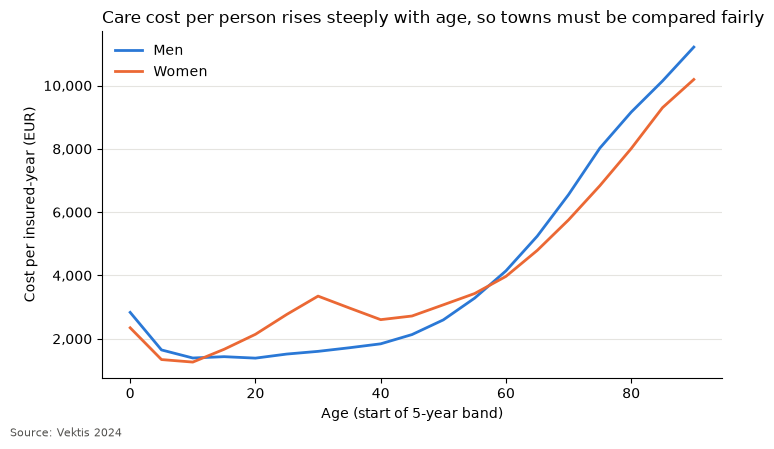

In [59]:
# Chart 1: why a fair comparison is needed (cost rises steeply with age, so towns with older people cost more), upgrading the chart I already have
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(men["age_from"], men["rate"], color="#2a78d6", linewidth=2, label="Men")
ax.plot(women["age_from"], women["rate"], color="#eb6834", linewidth=2, label="Women")

# Title states the finding; axes say what and in which unit
ax.set_title("Care cost per person rises steeply with age, so towns must be compared fairly", loc="left")
ax.set_xlabel("Age (start of 5-year band)")
ax.set_ylabel("Cost per insured-year (EUR)")
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")

# Quiet grid and frame, so the lines stand out
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

# Source line under the chart
fig.text(0.01, -0.02, "Source: Vektis 2024", fontsize=8, color="#52514e")

# Save before show (show clears the figure); tight keeps the source line in the image
fig.savefig("../figures/01_cost_by_age.png", dpi=150, bbox_inches="tight")
plt.show()


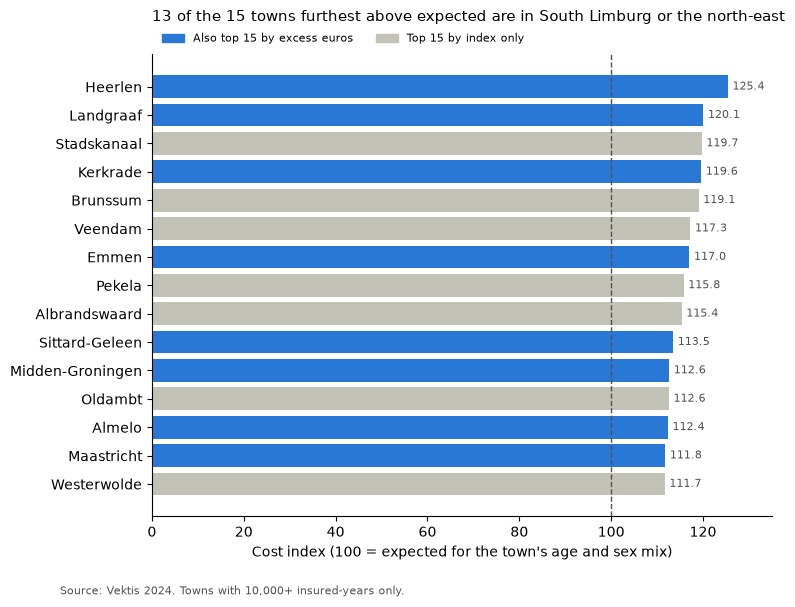

In [60]:
# Chart 2: where is cost highest relative to expected? Top 15 by cost index (size rule applied)
# Reverse the order so the highest bar is at the top (barh draws from the bottom up)
chart2 = top_index.iloc[::-1]
# Towns that are also in the top 15 by euros (4c) get the strong colour, the rest a quiet grey
colours2 = ["#2a78d6" if name in on_both else "#c3c2b7" for name in chart2["gemeentenaam"]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(chart2["gemeentenaam"].str.title(), chart2["cost_index"], color=colours2)

# Reference line at 100 = exactly as expected for the town's age and sex mix
ax.axvline(100, color="#52514e", linewidth=1, linestyle="--")

# Value at the end of each bar, so nobody has to read it off the axis
for y, value in enumerate(chart2["cost_index"]):
    ax.text(value + 1, y, f"{value:.1f}", va="center", fontsize=8, color="#52514e")

ax.set_title("13 of the 15 towns furthest above expected are in South Limburg or the north-east", loc="left", fontsize=11, pad=24)
ax.set_xlabel("Cost index (100 = expected for the town's age and sex mix)")
ax.set_xlim(0, 135)
ax.spines[["top", "right"]].set_visible(False)

# Legend for the two colours (made by hand, because the bars are one series)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2a78d6", label="Also top 15 by excess euros"),
                   Patch(color="#c3c2b7", label="Top 15 by index only")],
          frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8)

fig.text(0.01, -0.02, "Source: Vektis 2024. Towns with 10,000+ insured-years only.", fontsize=8, color="#52514e")
fig.savefig("../figures/02_top15_cost_index.png", dpi=150, bbox_inches="tight")
plt.show()


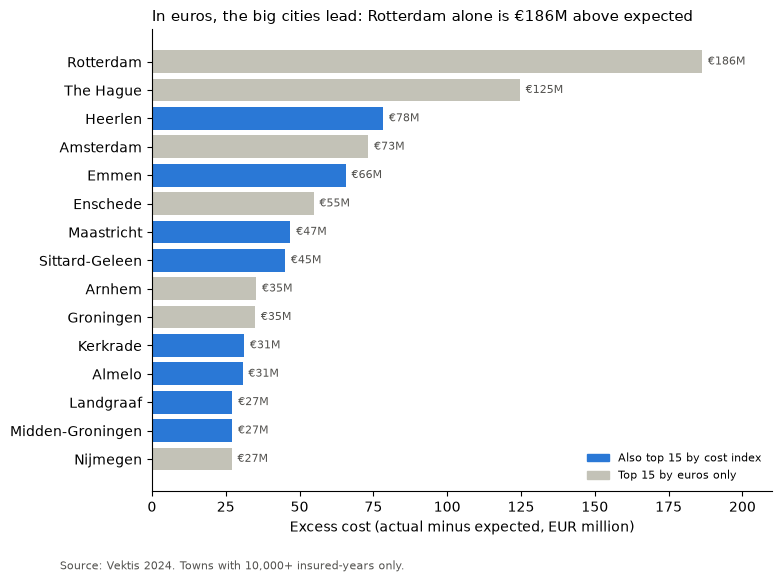

In [61]:
# Chart 3: how much money is at stake? Top 15 by excess euros (size rule applied)
chart3 = top_excess.iloc[::-1]
colours3 = ["#2a78d6" if name in on_both else "#c3c2b7" for name in chart3["gemeentenaam"]]
excess_m = chart3["excess"] / 1_000_000

fig, ax = plt.subplots(figsize=(8, 6))
# Vektis writes 's-Gravenhage as "S GRAVENHAGE"; show the usual name
ax.barh(chart3["gemeentenaam"].str.title().replace("S Gravenhage", "The Hague"), excess_m, color=colours3)

# Value at the end of each bar, in millions
for y, value in enumerate(excess_m):
    ax.text(value + 2, y, f"€{value:.0f}M", va="center", fontsize=8, color="#52514e")

ax.set_title("In euros, the big cities lead: Rotterdam alone is €186M above expected", loc="left", fontsize=11)
ax.set_xlabel("Excess cost (actual minus expected, EUR million)")
ax.set_xlim(0, 210)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[Patch(color="#2a78d6", label="Also top 15 by cost index"),
                   Patch(color="#c3c2b7", label="Top 15 by euros only")],
          frameon=False, loc="lower right", fontsize=8)

fig.text(0.01, -0.02, "Source: Vektis 2024. Towns with 10,000+ insured-years only.", fontsize=8, color="#52514e")
fig.savefig("../figures/03_top15_excess.png", dpi=150, bbox_inches="tight")
plt.show()


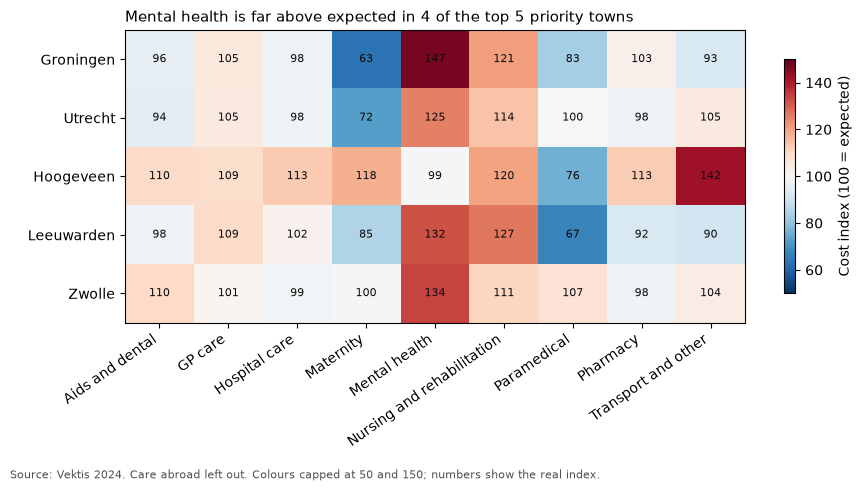

In [62]:
# Chart 4: what drives it? Care-type indexes for the top 5 priority towns
from matplotlib.colors import TwoSlopeNorm

top5 = priority.head(5)
# One row per town, one column per care type, cost_index in the cells (same pivot as in cleaning)
heat = care_type_town[care_type_town["Key"].isin(top5["Key"])].pivot(
    index="gemeentenaam", columns="care_type", values="cost_index"
)
# Keep the priority order (Groningen first) and nicer names
heat = heat.loc[top5["gemeentenaam"]]
heat.index = heat.index.str.title()
# Leave out care abroad: it depends on distance to the border, not on anything a contract review can change (Finding 5b)
heat = heat.drop(columns="Care abroad")

fig, ax = plt.subplots(figsize=(10, 3.8))
# Diverging colours: blue below 100, white at 100, red above; capped at 50 and 150 so one extreme cell cannot wash out the rest
norm = TwoSlopeNorm(vmin=50, vcenter=100, vmax=150)
image = ax.imshow(heat.clip(50, 150), cmap="RdBu_r", norm=norm, aspect="auto")

# Town names on the left, care types along the bottom
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xticks(range(len(heat.columns)), heat.columns, rotation=35, ha="right")

# The real index in every cell (not the capped one)
for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        ax.text(col, row, f"{heat.iloc[row, col]:.0f}", ha="center", va="center", fontsize=8, color="#0b0b0b")

fig.colorbar(image, ax=ax, label="Cost index (100 = expected)", shrink=0.8)
ax.set_title("Mental health is far above expected in 4 of the top 5 priority towns", loc="left", fontsize=11)
fig.text(0.01, -0.3, "Source: Vektis 2024. Care abroad left out. Colours capped at 50 and 150; numbers show the real index.", fontsize=8, color="#52514e")
fig.savefig("../figures/04_drivers_top5.png", dpi=150, bbox_inches="tight")
plt.show()


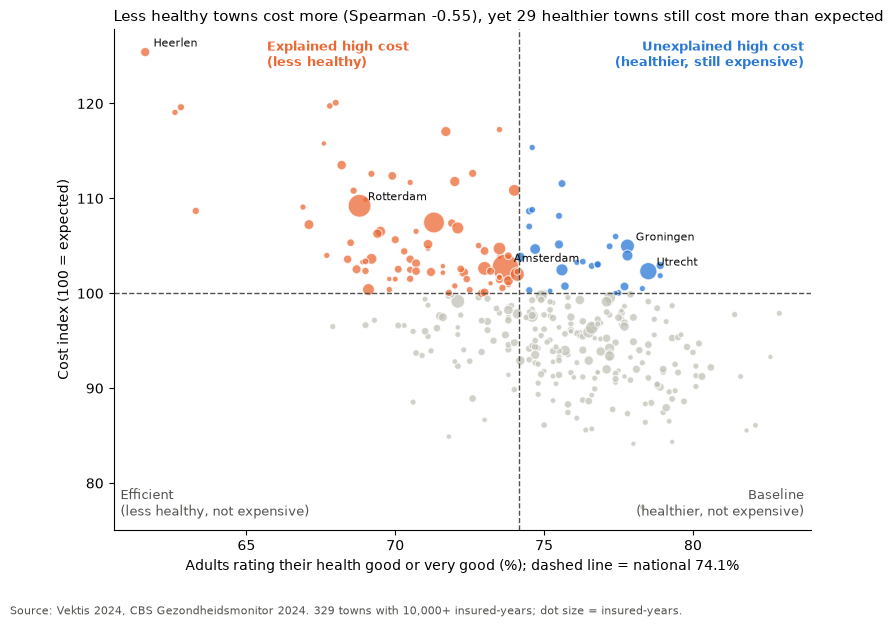

In [63]:
# Chart 5: is the high cost explained by health? One dot per big town, size = insured-years
fig, ax = plt.subplots(figsize=(9, 6.5))

# The two high-cost segments get a colour, the two others stay grey
segment_colours = {
    "Unexplained high cost": "#2a78d6",
    "Explained high cost": "#eb6834",
    "Baseline": "#c3c2b7",
    "Efficient": "#c3c2b7",
}
ax.scatter(big_towns["health_value"], big_towns["cost_index"],
           s=10 + big_towns["aantal_verzekerdejaren"] / 2500,
           c=big_towns["segment"].map(segment_colours),
           alpha=0.75, edgecolors="white", linewidths=0.8)

# Dividing lines: national health and an index of 100
ax.axvline(national_health, color="#52514e", linewidth=1, linestyle="--")
ax.axhline(100, color="#52514e", linewidth=1, linestyle="--")

# Name each corner (segment) in plain words
ax.text(0.99, 0.98, "Unexplained high cost\n(healthier, still expensive)", transform=ax.transAxes, ha="right", va="top", fontsize=9, color="#2a78d6", fontweight="bold")
ax.text(0.22, 0.98, "Explained high cost\n(less healthy)", transform=ax.transAxes, ha="left", va="top", fontsize=9, color="#eb6834", fontweight="bold")
ax.text(0.01, 0.02, "Efficient\n(less healthy, not expensive)", transform=ax.transAxes, ha="left", va="bottom", fontsize=9, color="#52514e")
ax.text(0.99, 0.02, "Baseline\n(healthier, not expensive)", transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="#52514e")

# Label a few towns the story mentions
for name in ["HEERLEN", "GRONINGEN", "UTRECHT", "AMSTERDAM", "ROTTERDAM"]:
    town = big_towns[big_towns["gemeentenaam"] == name].iloc[0]
    ax.annotate(name.title(), (town["health_value"], town["cost_index"]), xytext=(6, 4),
                textcoords="offset points", fontsize=8, color="#0b0b0b")

ax.set_title("Less healthy towns cost more (Spearman -0.55), yet 29 healthier towns still cost more than expected", loc="left", fontsize=11)
ax.set_xlabel(f"Adults rating their health good or very good (%); dashed line = national {national_health:.1f}%")
ax.set_ylabel("Cost index (100 = expected)")
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.02, "Source: Vektis 2024, CBS Gezondheidsmonitor 2024. 329 towns with 10,000+ insured-years; dot size = insured-years.", fontsize=8, color="#52514e")
fig.savefig("../figures/05_health_vs_cost.png", dpi=150, bbox_inches="tight")
plt.show()
